# Grasp: paper results

**Supplementary material** for *Grounding Is Not Enough: Testing Evidence
Sufficiency in LLM Reasoning over Knowledge Graphs*.

This notebook reproduces the numerical tables and statistical figures from the
selected results in `artifact/`. It covers the paper populations, RQ1 evidence
support, RQ2 support removal, RQ3 Grasp results, and the reported ablations.
Saved cell outputs allow immediate inspection.

From the extracted release directory, install the plotting dependencies and open
the notebook. Select **Kernel → Restart & Run All**:

```bash
python -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements-notebook.txt
python -m notebook local-results.ipynb
```

To execute without opening Jupyter, run `bash scripts/reproduce_results.sh`.
CSV tables and PDF/PNG figures are written to `runs/paper-results/`.
This workflow runs on a CPU and requires no model inference, API credentials,
dataset downloads, or LaTeX installation. Plot sizes are adapted for notebook
reading; the selected values and denominators are retained.

See `artifact/README.md` for result availability and
`docs/evaluation.md` for the evaluation contract.

## Setup

Paths are relative to this release directory. The notebook reads only the
bundled artifacts; provenance paths recorded inside them are not opened.

In [1]:
import json
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

matplotlib.use("Agg")
import matplotlib.pyplot as plt

ARTIFACT = Path("artifact")
OUTPUT = Path("runs/paper-results")
OUTPUT.mkdir(parents=True, exist_ok=True)

DATASETS = {"webqsp": "WebQSP", "cwq": "CWQ", "2wiki": "2WikiMultiHopQA"}
MODELS = {"qwen": "Qwen2.5-7B", "gemma": "Gemma-2-9B",
          "llama": "Llama-3.1-8B", "gpt6": "GPT-6 xhigh"}
STYLES = {
    "cot": ("CoT", "#332288", "D"),
    "gcr_multi": ("GCR*", "#EE7733", "s"),
    "dog": ("DoG", "#009988", "^"),
    "codex": ("Codex", "#CC3311", "P"),
    "ours": ("Grasp", "#0077BB", "o"),
}
BASELINES = ("cot", "gcr_multi", "dog", "codex")
plt.rcParams.update({"font.family": "DejaVu Serif", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.axisbelow": True, "grid.alpha": 0.2})

def read_json(relative_path):
    return json.loads((ARTIFACT / relative_path).read_text(encoding="utf-8"))

def show_table(frame, name, caption):
    frame.to_csv(OUTPUT / f"{name}.csv", index=False)
    display(Markdown(f"**{caption}**"))
    display(frame.style.format(precision=2).hide(axis="index"))

def save_figure(fig, name):
    fig.savefig(OUTPUT / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(OUTPUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=(OUTPUT / f"{name}.png").read_bytes()))

print(f"Python plotting stack: NumPy {np.__version__}, "
      f"pandas {pd.__version__}, Matplotlib {matplotlib.__version__}")

Python plotting stack: NumPy 1.26.4, pandas 2.2.3, Matplotlib 3.7.1


## 1. Populations and reporting definitions

**S** contains questions whose input knowledge provides sufficient support
for at least one gold answer; **I** contains questions without such support.
Sufficient support jointly satisfies the question's evaluation constraints
under consistent shared entity or value bindings. Evaluation-only constraints
are derived from benchmark annotations and are separate from Grasp's predicted
support specification. Unresolved questions are excluded from these paper
populations. CWQ uses the final curated population.

All displayed rates are percentages. Let $H_S$ count correct predictions on S,
$C_S$ count correct predictions with support in their returned evidence, and
$A_S,A_I$ count `Unknown` responses on S and I:

$$\mathrm{Hit@1}=100H_S/N_S,\quad
\mathrm{EvidenceHit@1}=100C_S/N_S,\quad
\mathrm{EvidenceGap}=100(1-C_S/H_S).$$
$$\mathrm{OAR}_S=100A_S/N_S,\quad \mathrm{CAR}_I=100A_I/N_I,\quad
\mathrm{EBA}=100(C_S+A_I)/(N_S+N_I).$$

EvidenceGap is undefined when $H_S=0$. EBA combines counts across S and I.
For support removal, APR = ATR_Same; Same, Other, Unknown, and error retain
the fixed intervention denominator. Errors are distinct from Unknown.

In [2]:
populations = read_json("splits/populations.json")
population_table = pd.DataFrame([
    {"Dataset": label, "S": populations[key]["paper"]["S"],
     "I": populations[key]["paper"]["I"],
     "Total": sum(populations[key]["paper"].values())}
    for key, label in DATASETS.items()
])
show_table(population_table, "populations", "Reported S/I populations")
cohorts = populations["cwq_interventions"]["paper"]
show_table(pd.DataFrame([{
    "Condition-loss pairs": cohorts["condition_loss"],
    "Binding-mismatch pairs": cohorts["binding_mismatch"],
    "Pooled intervention pairs": cohorts["condition_loss"] + cohorts["binding_mismatch"],
    "Progressive questions per level": cohorts["progressive"],
}]), "intervention_populations", "CWQ support-removal populations")

**Reported S/I populations**

Dataset,S,I,Total
WebQSP,1335,286,1621
CWQ,1679,1459,3138
2WikiMultiHopQA,1383,2614,3997


**CWQ support-removal populations**

Condition-loss pairs,Binding-mismatch pairs,Pooled intervention pairs,Progressive questions per level
295,120,415,268


## 2. RQ1: Do correct predictions have sufficient returned evidence?

The tables read `paper/main_tables.csv` at its reported precision. Hit@1 and
EvidenceHit@1 use the full S denominator. EvidenceGap measures the fraction
of correct predictions lacking sufficient support in the returned evidence.
Codex is the independent GPT-6 xhigh reference.

In [3]:
main = pd.read_csv(ARTIFACT / "paper/main_tables.csv")
main["Model"] = main["model"].map(MODELS)
main = main.rename(columns={"system": "System"})
for dataset, label in DATASETS.items():
    frame = main.loc[main["dataset"].eq(dataset),
                     ["Model", "System", "Hit@1", "EvidenceHit@1", "EvidenceGap"]]
    show_table(frame, f"rq1_{dataset}", f"{label}: answer correctness and evidence support (%)")

**WebQSP: answer correctness and evidence support (%)**

Model,System,Hit@1,EvidenceHit@1,EvidenceGap
Qwen2.5-7B,CoT,59.10,15.43,73.89
Qwen2.5-7B,GCR*,86.37,66.44,23.07
Qwen2.5-7B,DoG,73.11,56.10,23.26
Gemma-2-9B,CoT,43.52,11.01,74.70
Gemma-2-9B,GCR*,86.59,66.22,23.53
Gemma-2-9B,DoG,62.77,49.06,21.84
Llama-3.1-8B,CoT,54.16,23.90,55.88
Llama-3.1-8B,GCR*,88.54,67.79,23.43
Llama-3.1-8B,DoG,66.22,53.71,18.89
GPT-6 xhigh,Codex,84.12,74.76,11.13


**CWQ: answer correctness and evidence support (%)**

Model,System,Hit@1,EvidenceHit@1,EvidenceGap
Qwen2.5-7B,CoT,63.73,27.99,56.07
Qwen2.5-7B,GCR*,72.13,31.33,56.56
Qwen2.5-7B,DoG,61.94,30.73,50.38
Gemma-2-9B,CoT,49.97,13.70,72.59
Gemma-2-9B,GCR*,72.25,33.00,54.33
Gemma-2-9B,DoG,58.61,30.73,47.56
Llama-3.1-8B,CoT,46.81,25.13,46.31
Llama-3.1-8B,GCR*,73.32,34.19,53.37
Llama-3.1-8B,DoG,57.42,26.15,54.46
GPT-6 xhigh,Codex,89.52,67.30,24.82


**2WikiMultiHopQA: answer correctness and evidence support (%)**

Model,System,Hit@1,EvidenceHit@1,EvidenceGap
Qwen2.5-7B,CoT,46.49,14.03,69.83
Qwen2.5-7B,GCR*,75.20,36.59,51.35
Qwen2.5-7B,DoG,87.13,79.68,8.55
Gemma-2-9B,CoT,32.68,7.59,76.77
Gemma-2-9B,GCR*,73.90,31.16,57.83
Gemma-2-9B,DoG,83.73,70.93,15.28
Llama-3.1-8B,CoT,39.91,15.11,62.14
Llama-3.1-8B,GCR*,76.07,34.92,54.09
Llama-3.1-8B,DoG,84.16,74.91,11.00
GPT-6 xhigh,Codex,97.47,96.75,0.74


### Constraint count and question structure

The following panels use the frozen CWQ S stratum counts in
`paper/rq1_gap_data.json`. Each point divides unsupported correct predictions
by all correct predictions in that stratum. Structure groups may overlap.
CoT, GCR*, and DoG use Qwen2.5-7B; Codex uses GPT-6 xhigh.

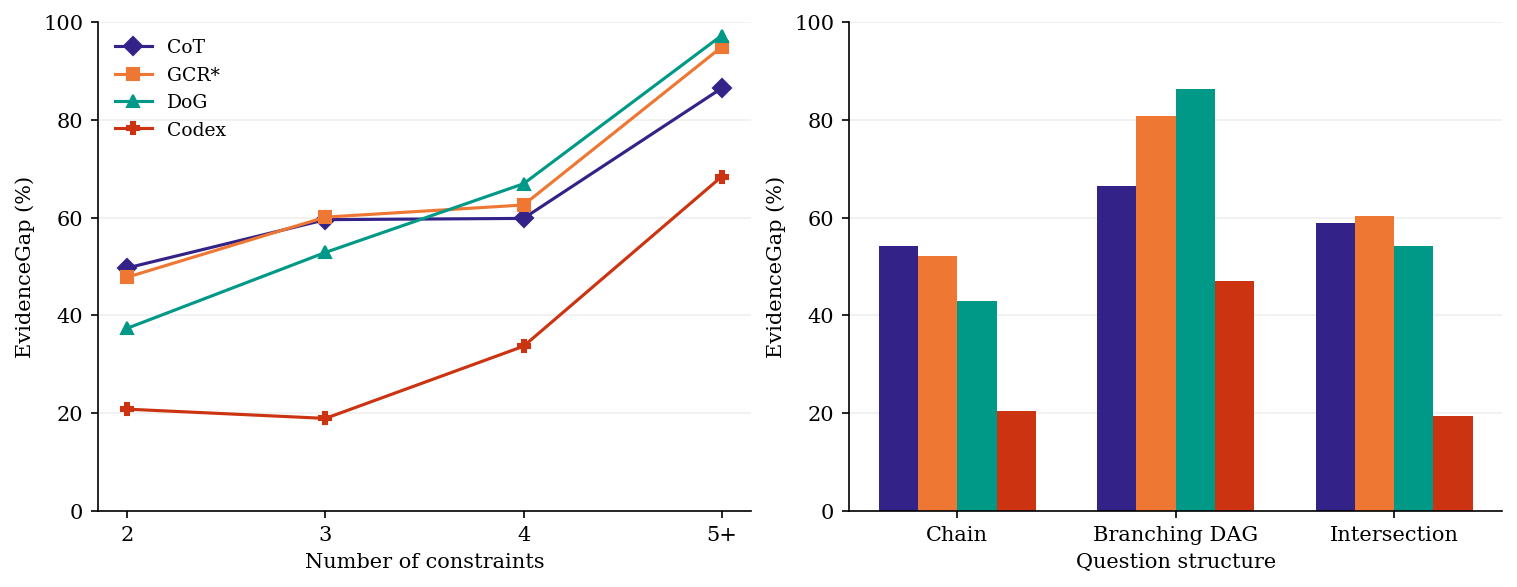

In [4]:
rq1 = read_json("paper/rq1_gap_data.json")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
strata_rows = []
for ax, group in zip(axes, ["gold_query_size", "contract_structure"]):
    data = rq1[group]
    x = np.arange(len(data["order"]))
    for offset, system in enumerate(BASELINES):
        label, color, marker = STYLES[system]
        values = []
        for stratum in data["order"]:
            counts = data["strata"][stratum]["systems"][system]
            gap = 100 * counts["count"] / counts["denominator"]
            values.append(gap)
            strata_rows.append({"Group": "Constraint count" if group == "gold_query_size" else "Question structure",
                                "Stratum": stratum if group == "gold_query_size" else data["display_names"][stratum],
                                "System": label,
                                "Unsupported correct": counts["count"],
                                "Correct": counts["denominator"], "EvidenceGap": gap})
        if group == "gold_query_size":
            ax.plot(x, values, color=color, marker=marker, label=label)
        else:
            ax.bar(x + (offset - 1.5) * 0.18, values, width=0.18, color=color, label=label)
    labels = data["order"] if group == "gold_query_size" else [
        data["display_names"][key] for key in data["order"]]
    ax.set(xticks=x, xticklabels=labels, ylim=(0, 100), ylabel="EvidenceGap (%)")
    ax.grid(axis="y")
axes[0].set_xlabel("Number of constraints")
axes[1].set_xlabel("Question structure")
axes[0].legend(frameon=False, fontsize=9)
pd.DataFrame(strata_rows).to_csv(OUTPUT / "rq1_strata.csv", index=False)
save_figure(fig, "rq1_constraint_count_and_structure")

### Textual similarity of relations

These curves keep the original 1,679-question CWQ S split, predictions, and
returned evidence fixed. Exact matching and seven cosine-similarity thresholds
are reported. Relaxation accepts additional relation matches; the other replay
criteria, including shared bindings, remain unchanged. The eight Codex points
are repeated across panels. The 80 distinct curve points come from
`analysis/semantic_relaxation/metrics.csv`.

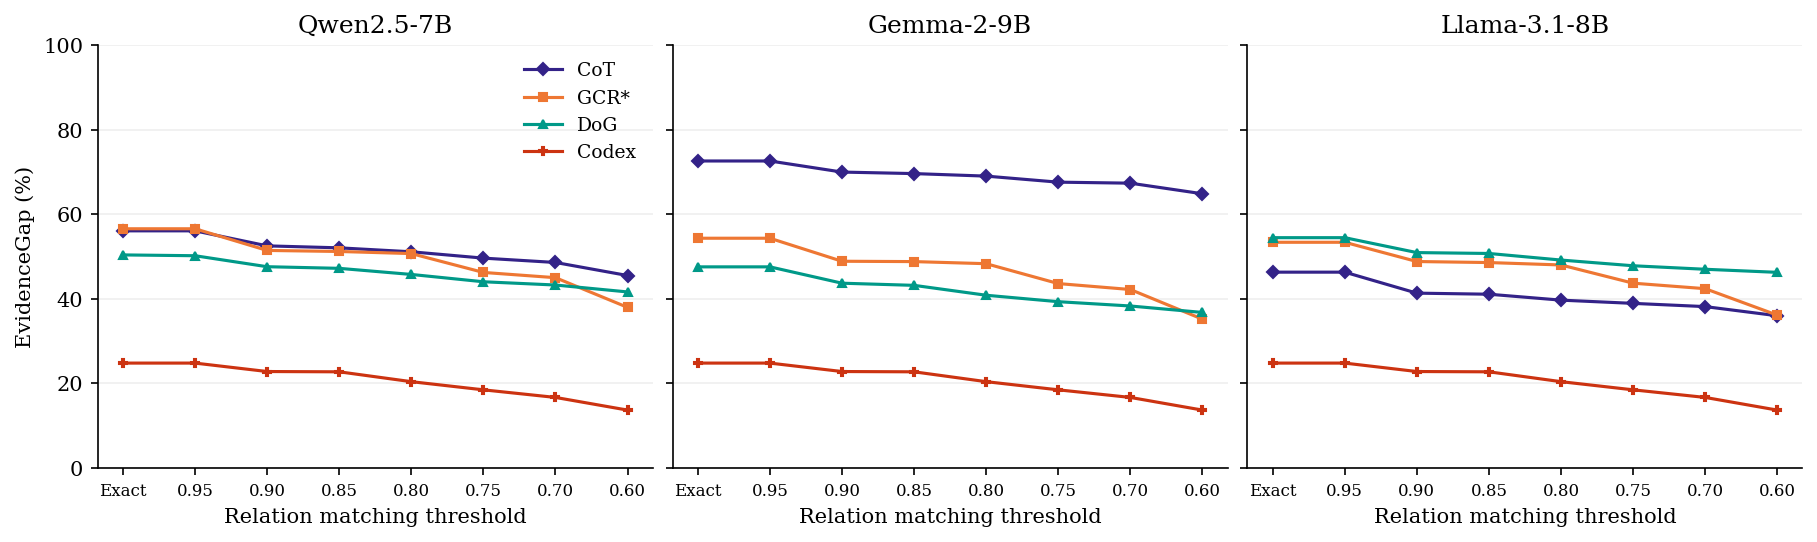

In [5]:
semantic = pd.read_csv(ARTIFACT / "analysis/semantic_relaxation/metrics.csv")
settings = semantic["setting"].drop_duplicates().tolist()
thresholds = semantic.drop_duplicates("setting")["threshold"].iloc[1:]
setting_labels = ["Exact"] + [f"{value:.2f}" for value in thresholds]
semantic_models = ["Qwen-2.5-7B", "Gemma-2-9B", "Llama-3.1-8B"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True, layout="constrained")
for ax, model in zip(axes, semantic_models):
    panel = semantic.loc[semantic["model"].isin([model, "Codex GPT 6 xhigh"])]
    for system in BASELINES:
        label, color, marker = STYLES[system]
        curve = panel.loc[panel["method"].eq(label)].set_index("setting").loc[settings]
        gap = 100 * curve["gap_count"] / curve["H_K"]
        ax.plot(setting_labels, gap, color=color, marker=marker, label=label, markersize=4)
    ax.set(title=model.replace("Qwen-2.5", "Qwen2.5"), xlabel="Relation matching threshold", ylim=(0, 100))
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="y")
axes[0].set_ylabel("EvidenceGap (%)")
axes[0].legend(frameon=False, fontsize=9)
semantic_export = pd.DataFrame({
    "Matching": semantic["setting"].map(dict(zip(settings, setting_labels))),
    "Model": semantic["model"].replace({"Qwen-2.5-7B": "Qwen2.5-7B",
                                         "Codex GPT 6 xhigh": "GPT-6 xhigh"}),
    "System": semantic["method"], "N_S": semantic["N_K"],
    "Correct on S": semantic["H_K"], "Correct and supported on S": semantic["C_K"],
    "Correct without sufficient support": semantic["gap_count"],
    "Hit@1": 100 * semantic["Hit_at_1"],
    "EvidenceHit@1": 100 * semantic["EvidenceHit_at_1"],
    "EvidenceGap": 100 * semantic["EvidenceGap"],
})
semantic_export.to_csv(OUTPUT / "semantic_relaxation.csv", index=False)
save_figure(fig, "rq1_semantic_relaxation")

## 3. RQ2: Do grounded LLMs respect the evidence boundary when support is unavailable?

CAR_I measures Unknown responses on I; OAR_S measures Unknown responses on S.
The natural-graph tables use the same selected runs as RQ1.

In [6]:
for dataset, label in DATASETS.items():
    frame = main.loc[main["dataset"].eq(dataset),
                     ["Model", "System", "CAR_I", "OAR_S", "EBA"]]
    show_table(frame, f"rq2_natural_{dataset}", f"{label}: evidence-bounded decisions (%)")

**WebQSP: evidence-bounded decisions (%)**

Model,System,CAR_I,OAR_S,EBA
Qwen2.5-7B,CoT,0.35,0.15,12.77
Qwen2.5-7B,GCR*,5.59,1.35,55.71
Qwen2.5-7B,DoG,4.90,0.37,47.07
Gemma-2-9B,CoT,0.70,0.15,9.19
Gemma-2-9B,GCR*,5.59,0.82,55.52
Gemma-2-9B,DoG,11.19,0.97,42.38
Llama-3.1-8B,CoT,0.00,0.00,19.68
Llama-3.1-8B,GCR*,5.94,1.20,56.88
Llama-3.1-8B,DoG,0.35,0.00,44.29
GPT-6 xhigh,Codex,45.10,9.21,69.52


**CWQ: evidence-bounded decisions (%)**

Model,System,CAR_I,OAR_S,EBA
Qwen2.5-7B,CoT,0.00,0.00,14.98
Qwen2.5-7B,GCR*,11.58,12.63,22.15
Qwen2.5-7B,DoG,0.75,0.12,16.79
Gemma-2-9B,CoT,0.00,0.00,7.33
Gemma-2-9B,GCR*,11.93,13.52,23.20
Gemma-2-9B,DoG,0.07,0.00,16.48
Llama-3.1-8B,CoT,0.00,0.00,13.45
Llama-3.1-8B,GCR*,11.45,12.69,23.61
Llama-3.1-8B,DoG,0.00,0.00,13.99
GPT-6 xhigh,Codex,88.14,7.50,76.99


**2WikiMultiHopQA: evidence-bounded decisions (%)**

Model,System,CAR_I,OAR_S,EBA
Qwen2.5-7B,CoT,0.42,0.00,5.13
Qwen2.5-7B,GCR*,27.31,7.52,30.52
Qwen2.5-7B,DoG,9.41,0.00,33.73
Gemma-2-9B,CoT,0.65,0.00,3.05
Gemma-2-9B,GCR*,30.53,9.91,30.75
Gemma-2-9B,DoG,18.90,0.43,36.90
Llama-3.1-8B,CoT,0.04,0.00,5.25
Llama-3.1-8B,GCR*,26.43,8.24,29.37
Llama-3.1-8B,DoG,4.17,0.14,28.65
GPT-6 xhigh,Codex,62.47,0.43,74.33


### Condition loss and binding mismatch

Family-specific APR uses 295 condition-loss pairs or 120 binding-mismatch pairs.
Pooled transition rates use 415 pairs; a question can appear in both families.
`paper/support_removal_table.csv` retains the paper-reviewed classifications.
In this table, the paper's DoG Other display includes errors; the underlying
per-question error states remain distinct. Codex interventions use changed
prompts, contexts, and tools relative to the original-answer reference.

In [7]:
removal = pd.read_csv(ARTIFACT / "paper/support_removal_table.csv")
removal["model"] = removal["model"].map(MODELS)
removal = removal.rename(columns={"model": "Model", "system": "System",
                                  "APR_condition_loss": "APR: condition loss",
                                  "APR_binding_mismatch": "APR: binding mismatch"})
show_table(removal, "rq2_primary_interventions", "Primary support-removal results (%)")

**Primary support-removal results (%)**

Model,System,APR: condition loss,APR: binding mismatch,ATR_Same,ATR_Unknown,ATR_Other
Qwen2.5-7B,CoT,46.10,63.33,51.08,0.24,48.67
Qwen2.5-7B,GCR*,55.25,50.83,53.98,18.31,27.71
Qwen2.5-7B,DoG,53.56,50.00,52.53,3.37,44.10
Gemma-2-9B,CoT,63.39,62.50,63.13,0.00,36.87
Gemma-2-9B,GCR*,52.54,47.50,51.08,18.31,30.60
Gemma-2-9B,DoG,59.66,61.67,60.24,5.78,33.98
Llama-3.1-8B,CoT,61.36,72.50,64.58,0.00,35.42
Llama-3.1-8B,GCR*,55.59,49.17,53.73,16.39,29.88
Llama-3.1-8B,DoG,51.86,55.00,52.77,0.72,46.51
GPT-6 xhigh,Codex,8.81,20.83,12.29,85.30,2.41


### Progressive support removal

The same 268 questions are evaluated at each level $k=0,1,2$.
APR and transition rates are calculated directly from the counts in
`paper/rq2_figure_data.csv`. Codex has five missing original answers at $k=0$;
they remain errors in the denominator and appear as hatched areas.

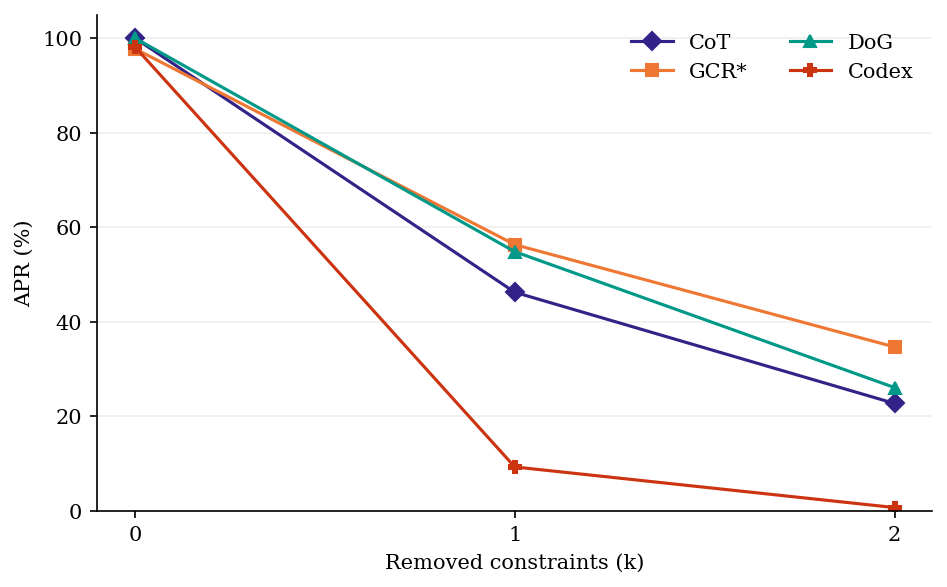

In [8]:
progressive = pd.read_csv(ARTIFACT / "paper/rq2_figure_data.csv")
fig, ax = plt.subplots(figsize=(6.2, 3.8), layout="constrained")
for system in BASELINES:
    frame = progressive.loc[progressive["system"].eq(system)].sort_values("k")
    label, color, marker = STYLES[system]
    ax.plot(frame["k"], 100 * frame["same_answer_count"] / frame["denominator"],
            color=color, marker=marker, label=label)
ax.set(xticks=[0, 1, 2], ylim=(0, 105), xlabel="Removed constraints (k)", ylabel="APR (%)")
ax.grid(axis="y")
ax.legend(frameon=False, ncol=2)
progressive_export = progressive.rename(columns={
    "system": "System", "denominator": "N", "same_answer_count": "Same count",
    "other_answer_count": "Other count", "abstention_count": "Unknown count",
    "error_count": "Error count", "same_answer_percent": "ATR_Same",
    "other_answer_percent": "ATR_Other", "abstention_percent": "ATR_Unknown",
    "error_percent": "Error (%)",
})
progressive_export["System"] = progressive_export["System"].map(
    {key: style[0] for key, style in STYLES.items()})
progressive_export.to_csv(OUTPUT / "rq2_progressive_counts.csv", index=False)
save_figure(fig, "rq2_progressive_apr")

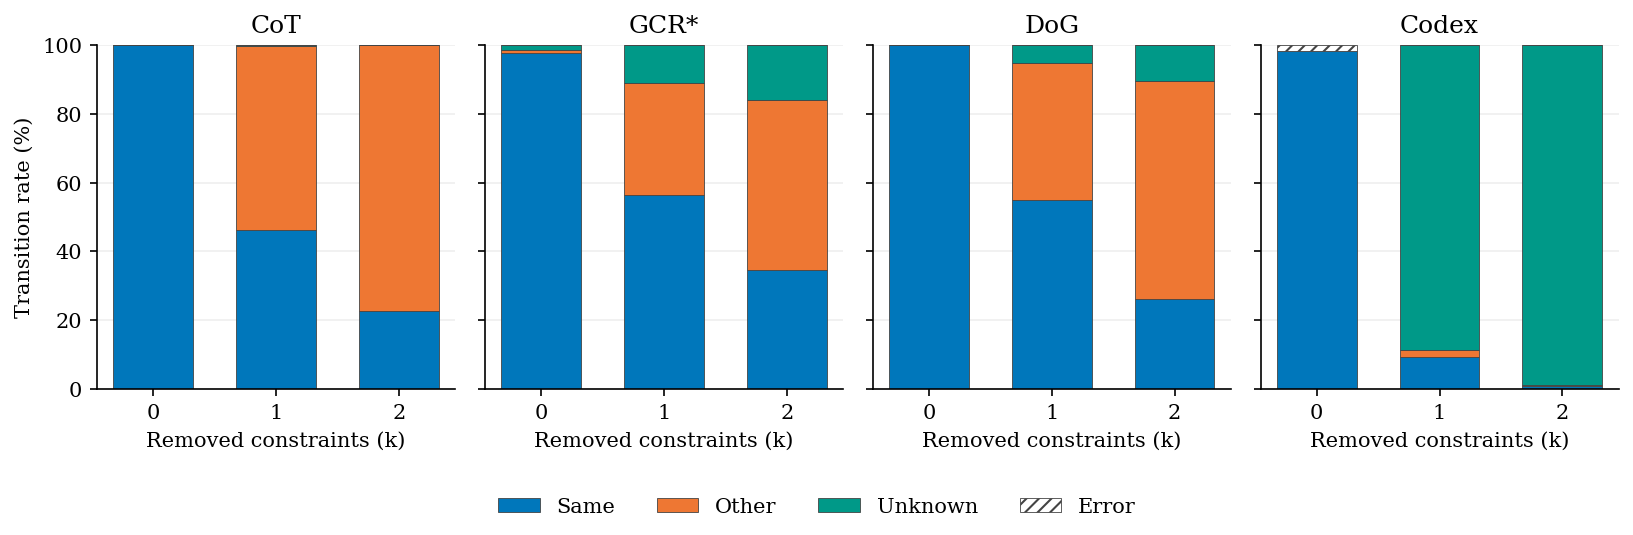

In [9]:
transitions = [("same_answer", "Same", "#0077BB"),
               ("other_answer", "Other", "#EE7733"),
               ("abstention", "Unknown", "#009988"),
               ("error", "Error", "white")]
fig, axes = plt.subplots(1, 4, figsize=(11, 3.6), sharey=True)
for ax, system in zip(axes, BASELINES):
    frame = progressive.loc[progressive["system"].eq(system)].sort_values("k")
    bottom = np.zeros(len(frame))
    for state, label, color in transitions:
        values = 100 * frame[f"{state}_count"].to_numpy() / frame["denominator"].to_numpy()
        ax.bar(frame["k"], values, bottom=bottom, width=0.65, color=color,
               label=label, edgecolor="#444444", linewidth=0.4,
               hatch="////" if state == "error" else None)
        bottom += values
    ax.set(title=STYLES[system][0], xticks=[0, 1, 2], ylim=(0, 100), xlabel="Removed constraints (k)")
    ax.grid(axis="y")
axes[0].set_ylabel("Transition rate (%)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.10, 1, 1))
save_figure(fig, "rq2_progressive_transitions")

## 4. RQ3: Do explicit support specifications improve evidence-bounded behavior?

Grasp (Grounding with Requirement-Aware Shared-binding Preservation) is a
training-free framework with three stages: **support specification induction**,
**specification-guided grounding**, and **evidence-bounded answering**.
A predicted support specification expresses evidence requirements and shared
bindings. Grounding preserves these bindings, and a specification-aware
answerer assesses the resulting evidence, returning an answer with citations
or `Unknown`. All model components remain frozen.

Model labels below identify the grounding scorer; support specification
induction and evidence-bounded answering use GPT-OSS-120B. Natural-graph values are read from the selected radar inputs at
their stored precision. WebQSP Grasp/Qwen uses the paper-selected support and
abstention sources. Gemma/Llama on WebQSP and 2WikiMultiHopQA have aggregate results
only; their per-question Grasp predictions are not included in this bundle.

In [10]:
radar = {"cwq": read_json("paper/rq3_radar_data.json"),
         **read_json("paper/rq3_appendix_data.json")["datasets"]}
metric_fields = {"Hit@1": "hit", "EvidenceHit@1": "evidence_hit",
                 "EvidenceGap": "normalized_gap", "CAR_I": "car",
                 "OAR_S": "oar", "EBA": "eba"}
grasp_rows = []
for dataset, label in DATASETS.items():
    for model, panel in radar[dataset]["models"].items():
        values = panel["systems"]["ours"]
        grasp_rows.append({"Dataset": label, "Grounding model": MODELS[model],
                           **{metric: values[field] for metric, field in metric_fields.items()}})
show_table(pd.DataFrame(grasp_rows), "rq3_grasp_natural", "Grasp on natural input graphs (%)")

grasp_removal = []
for model in ["qwen", "gemma", "llama"]:
    families = [read_json(f"interventions/{family}/grasp/{model}/metrics.json")
                for family in ["condition_loss", "binding_mismatch"]]
    denominator = sum(family["N"] for family in families)
    grasp_removal.append({
        "Grounding model": MODELS[model],
        "APR: condition loss": families[0]["APR"]["percent"],
        "APR: binding mismatch": families[1]["APR"]["percent"],
        **{metric: 100 * sum(family["counts"][state] for family in families) / denominator
           for metric, state in [("ATR_Same", "same_answer"),
                                 ("ATR_Other", "other_answer"), ("ATR_Unknown", "abstention")]},
    })
show_table(pd.DataFrame(grasp_removal), "rq3_grasp_interventions", "Grasp after support removal (%)")

**Grasp on natural input graphs (%)**

Dataset,Grounding model,Hit@1,EvidenceHit@1,EvidenceGap,CAR_I,OAR_S,EBA
WebQSP,Qwen2.5-7B,80.52,68.46,14.98,55.94,12.66,66.26
WebQSP,Gemma-2-9B,79.40,68.54,13.68,58.39,14.76,66.75
WebQSP,Llama-3.1-8B,80.07,67.42,15.81,60.14,14.16,66.13
CWQ,Qwen2.5-7B,81.30,58.96,27.47,85.74,12.92,71.41
CWQ,Gemma-2-9B,79.21,57.06,27.97,88.01,15.01,71.45
CWQ,Llama-3.1-8B,81.30,57.30,29.52,87.11,13.22,71.16
2WikiMultiHopQA,Qwen2.5-7B,90.67,85.18,6.06,70.05,6.94,75.28
2WikiMultiHopQA,Gemma-2-9B,90.46,85.83,5.12,70.54,7.23,75.83
2WikiMultiHopQA,Llama-3.1-8B,91.18,85.47,6.26,69.51,6.80,75.03


**Grasp after support removal (%)**

Grounding model,APR: condition loss,APR: binding mismatch,ATR_Same,ATR_Other,ATR_Unknown
Qwen2.5-7B,9.15,10.83,9.64,4.34,86.02
Gemma-2-9B,11.53,10.83,11.33,3.37,84.82
Llama-3.1-8B,10.17,10.83,10.36,3.86,85.06


### Evidence-bounded performance across datasets

These panels show the paper's GCR*, Codex, and Grasp comparison. Every axis is
oriented so that a larger value is better: Hit@1, EvidenceHit@1 (E-Hit),
100 − EvidenceGap, EBA, 100 − OAR_S, and CAR_I. CWQ additionally includes
100 − APR, with APR pooled from the two intervention families by pair count.
WebQSP and 2WikiMultiHopQA have no APR axis. Codex is the same independent reference
across grounding-model panels.

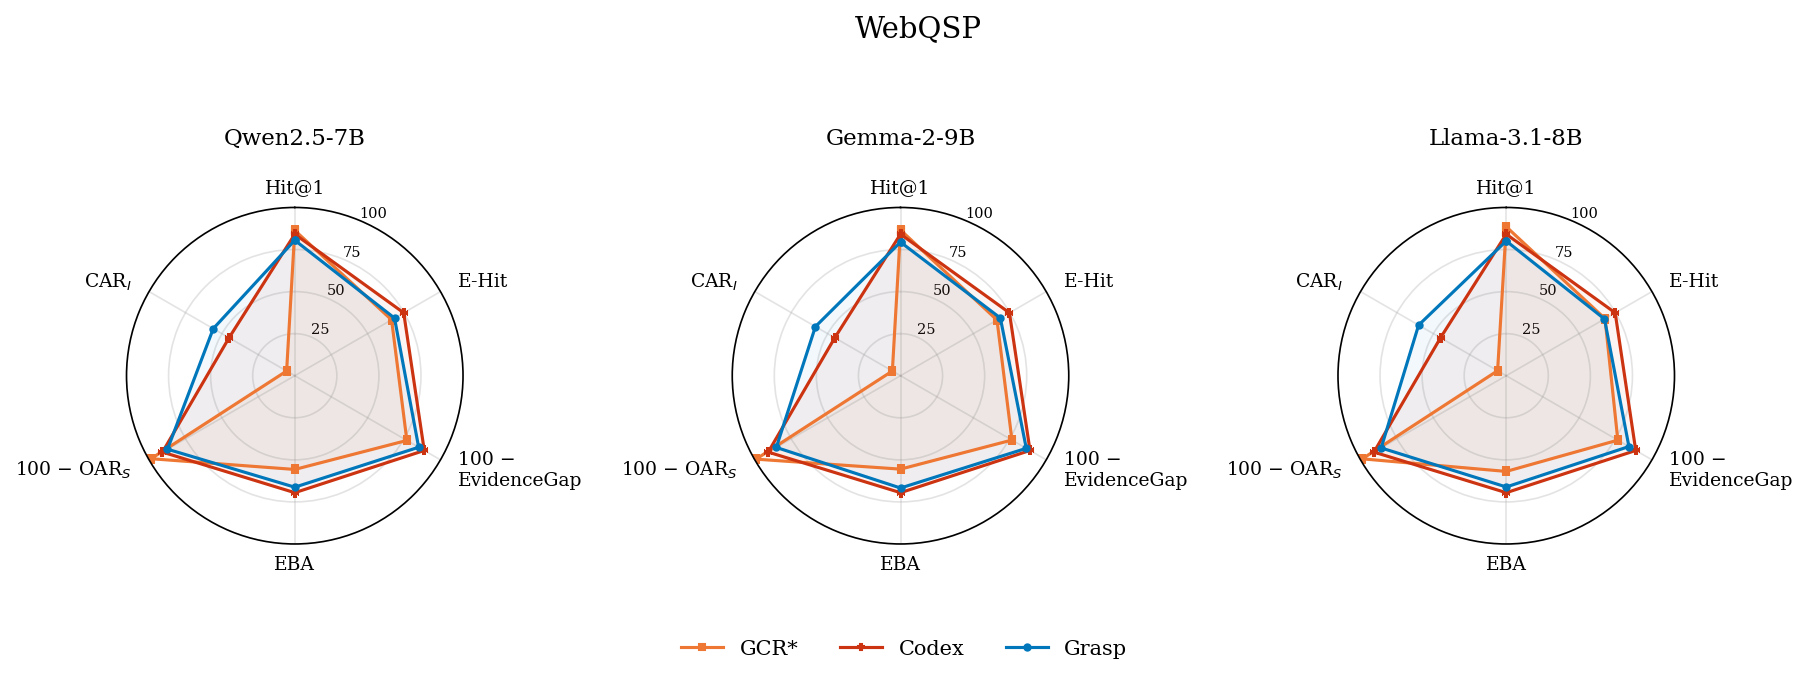

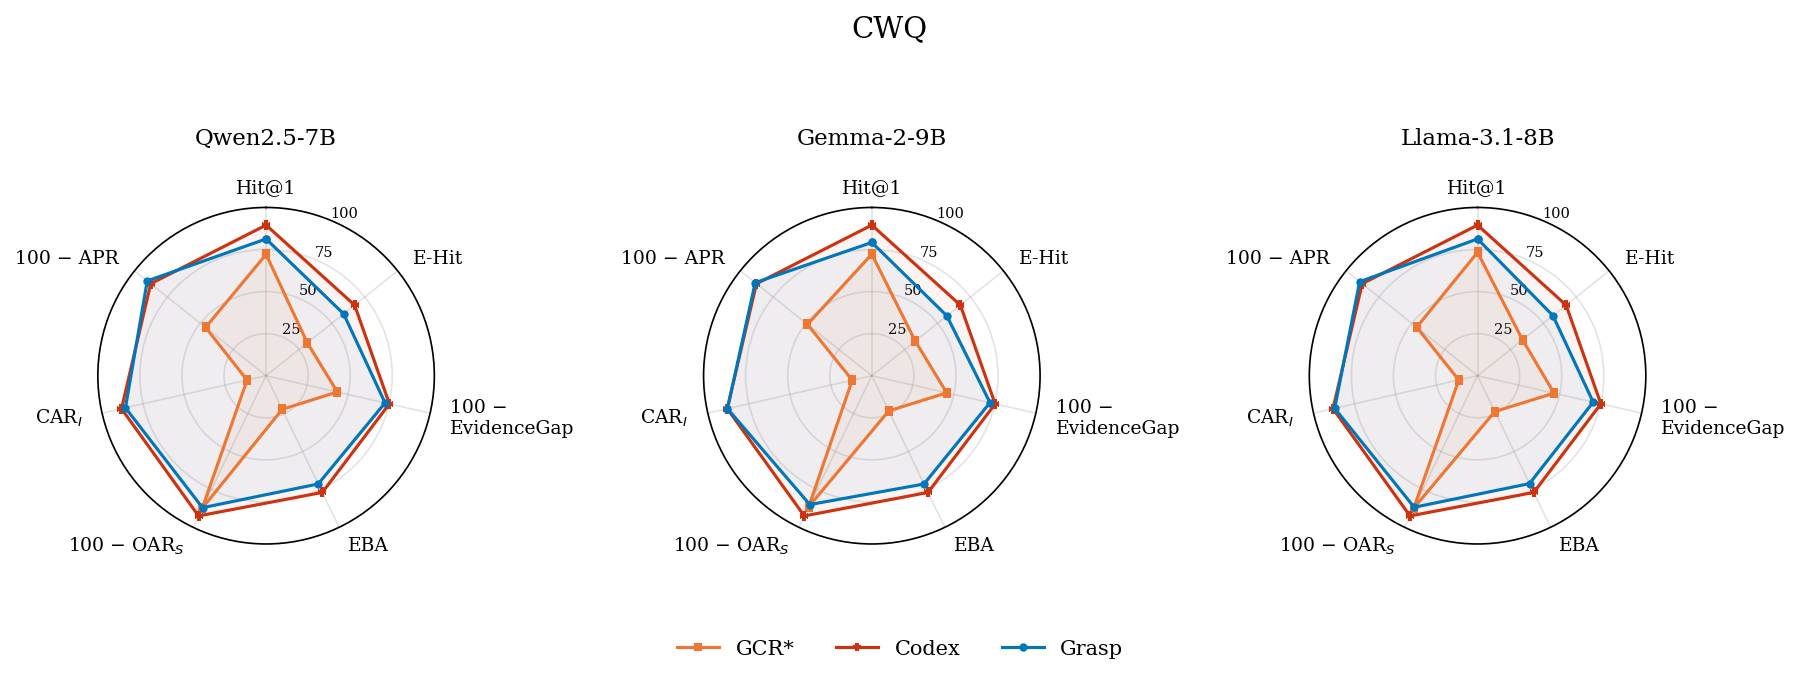

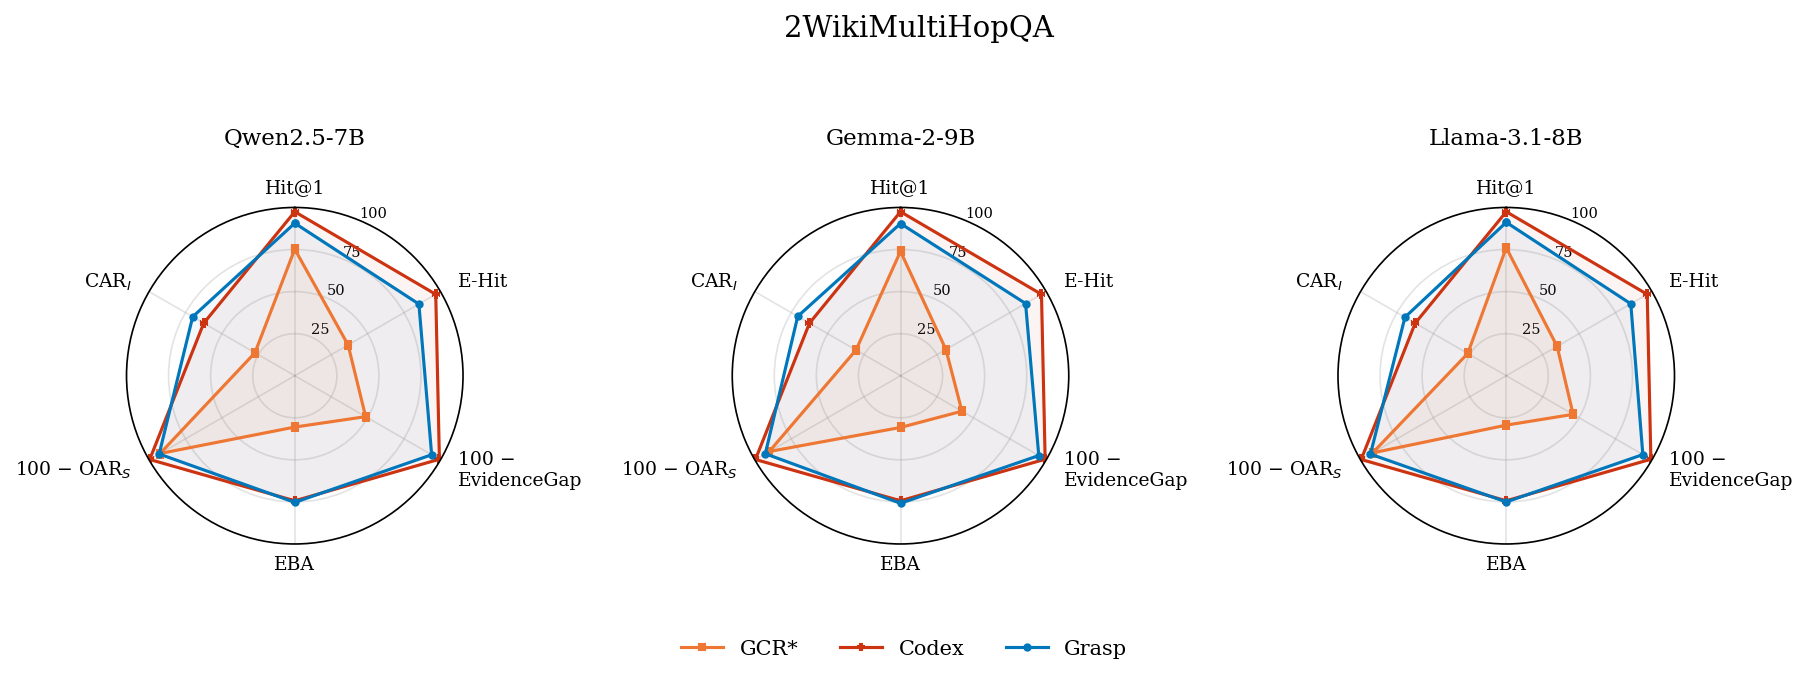

In [11]:
for dataset, dataset_label in DATASETS.items():
    labels = ["Hit@1", "E-Hit", "100 −\nEvidenceGap", "EBA", "100 − OAR$_S$", "CAR$_I$"]
    if dataset == "cwq":
        labels.append("100 − APR")
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False)
    closed_angles = np.append(angles, angles[0])
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.3), subplot_kw={"projection": "polar"})
    for ax, model in zip(axes, ["qwen", "gemma", "llama"]):
        for system in ["gcr_multi", "codex", "ours"]:
            point = radar[dataset]["models"][model]["systems"][system]
            values = [point["hit"], point["evidence_hit"], 100 - point["normalized_gap"],
                      point["eba"], 100 - point["oar"], point["car"]]
            if dataset == "cwq":
                same = point["same_condition_loss"] + point["same_binding_mismatch"]
                pairs = cohorts["condition_loss"] + cohorts["binding_mismatch"]
                values.append(100 - 100 * same / pairs)
            label, color, marker = STYLES[system]
            closed_values = values + values[:1]
            ax.plot(closed_angles, closed_values, color=color, marker=marker,
                    markersize=3, linewidth=1.5, label=label)
            ax.fill(closed_angles, closed_values, color=color, alpha=0.05)
        ax.set_theta_offset(np.pi / 2)
        ax.set_theta_direction(-1)
        ax.set_xticks(angles, [])
        for angle, label in zip(angles, labels):
            horizontal = "left" if np.sin(angle) > 0.1 else "right" if np.sin(angle) < -0.1 else "center"
            ax.text(angle, 112, label, ha=horizontal, va="center", fontsize=9, clip_on=False)
        ax.set(ylim=(0, 100), yticks=[25, 50, 75, 100])
        ax.tick_params(axis="y", labelsize=7)
        ax.set_title(MODELS[model], pad=30, fontsize=11)
        ax.grid(alpha=0.35)
    fig.suptitle(dataset_label, fontsize=14, y=1.02)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False)
    fig.subplots_adjust(left=0.06, right=0.92, bottom=0.12, top=0.8, wspace=0.8)
    save_figure(fig, f"rq3_radar_{dataset}")

## 5. Component and grounding-model-size analyses

CWQ component results remove one design element at a time. The grounding-size
analysis varies the Qwen2.5 scorer while keeping support specification induction
and evidence-bounded answering fixed.
The 7B reference reuses Grasp (full); it is not a separate run. The tables read
`paper/components.csv` and `paper/scorer_size.csv`.

In [12]:
components = pd.read_csv(ARTIFACT / "paper/components.csv").drop(columns="artifact")
components["model"] = components["model"].map(MODELS)
components["condition"] = components["condition"].map({
    "full": "Grasp (full)", "no_plan_structure": "w/o specification-aware answering",
    "no_domain_range_types": "w/o relation guidance",
    "without_binding_joins": "w/o binding consistency",
})
components = components.rename(columns={"model": "Grounding model", "condition": "Configuration"})
show_table(components, "grasp_components", "Grasp component analysis on CWQ (%)")
scorer = pd.read_csv(ARTIFACT / "paper/scorer_size.csv").drop(columns="artifact")
scorer = scorer.rename(columns={"grounding_model": "Grounding model"})
show_table(scorer, "grasp_scorer_size", "Grounding-model size on CWQ (%)")

**Grasp component analysis on CWQ (%)**

Grounding model,Configuration,Hit@1,EvidenceHit@1,OAR_S,CAR_I,EBA
Qwen2.5-7B,w/o specification-aware answering,78.20,52.23,17.09,86.29,68.07
Qwen2.5-7B,w/o relation guidance,79.39,57.24,14.83,87.05,71.10
Qwen2.5-7B,w/o binding consistency,74.39,53.72,15.37,86.57,68.99
Qwen2.5-7B,Grasp (full),81.30,58.96,12.92,85.74,71.41
Llama-3.1-8B,w/o specification-aware answering,78.98,49.97,15.90,86.36,66.89
Llama-3.1-8B,w/o relation guidance,78.62,56.76,15.31,86.36,70.52
Llama-3.1-8B,w/o binding consistency,75.40,51.94,14.77,85.54,67.56
Llama-3.1-8B,Grasp (full),81.30,57.30,13.22,87.11,71.16
Gemma-2-9B,w/o specification-aware answering,77.07,49.49,18.11,87.39,67.11
Gemma-2-9B,w/o relation guidance,77.78,55.99,15.90,88.14,70.94


**Grounding-model size on CWQ (%)**

Grounding model,Hit@1,EvidenceHit@1,EvidenceGap,CAR_I,OAR_S,EBA
Qwen2.5-1.5B,68.08,47.17,30.71,88.42,26.03,66.35
Qwen2.5-7B,81.30,58.96,27.47,85.74,12.92,71.41
Qwen2.5-32B,84.46,60.51,28.35,85.47,10.84,72.12


## 6. CWQ partition stability under semantic relaxation

This analysis replays constraints on each **full input graph** and recomputes
S/I membership across all 3,138 CWQ questions. It is separate from the RQ1
curves, which keep the original S split fixed and assess returned evidence.
Changed percentages use the full 3,138-question denominator. Only I → S
transitions occur in the recorded settings.

**CWQ partition changes**

Matching,S,I,I to S,Changed (%)
Exact,1679,1459,0,0.00
0.95,1688,1450,9,0.29
0.90,1696,1442,17,0.54
0.85,1706,1432,27,0.86
0.80,1718,1420,39,1.24
0.75,1725,1413,46,1.47
0.70,1728,1410,49,1.56
0.60,1750,1388,71,2.26


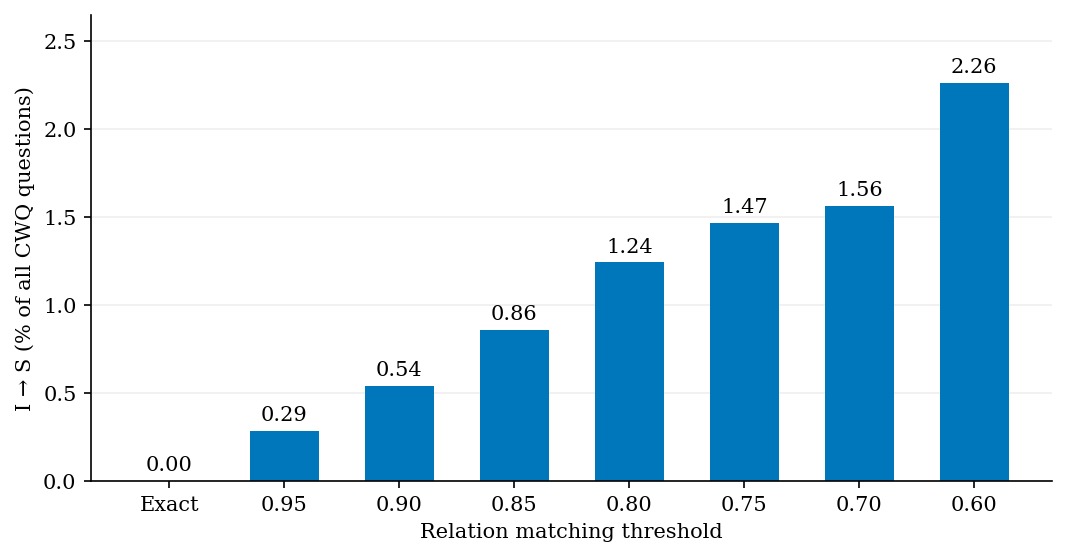

In [13]:
partition = pd.read_csv(ARTIFACT / "analysis/partition_relaxation/metrics.csv")
partition = partition.set_index("setting").loc[settings]
partition_table = pd.DataFrame({
    "Matching": setting_labels,
    "S": (partition["K_to_K"] + partition["U_to_K"]).to_numpy(),
    "I": (partition["K_to_U"] + partition["U_to_U"]).to_numpy(),
    "I to S": partition["U_to_K"].to_numpy(),
    "Changed (%)": (100 * partition["U_to_K"] / partition["N"]).to_numpy(),
})
show_table(partition_table, "cwq_partition_relaxation", "CWQ partition changes")
fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
bars = ax.bar(setting_labels, partition_table["Changed (%)"], color="#0077BB", width=0.6)
ax.bar_label(bars, labels=[f"{value:.2f}" for value in partition_table["Changed (%)"]], padding=3)
ax.set(ylim=(0, 2.65), xlabel="Relation matching threshold", ylabel="I → S (% of all CWQ questions)")
ax.grid(axis="y")
save_figure(fig, "cwq_partition_relaxation")

## 7. Outputs and source records

The generated CSV files contain the displayed tables and curve data. Each
figure is saved as a vector PDF and a PNG. Available per-question results,
selected configurations, and population memberships remain in `artifact/`.
`artifact/index.json` identifies each condition and its
available records; `artifact/sources.tsv` records source
selections. The notebook redraws recorded results and does not rerun prediction
scoring, evidence replay, or model inference.

In [14]:
outputs = sorted(path.name for path in OUTPUT.iterdir() if path.is_file())
display(Markdown("Exports in `runs/paper-results/`:\n\n" + "\n".join(
    f"- `{name}`" for name in outputs)))

Exports in `runs/paper-results/`:

- `cwq_partition_relaxation.csv`
- `cwq_partition_relaxation.pdf`
- `cwq_partition_relaxation.png`
- `grasp_components.csv`
- `grasp_scorer_size.csv`
- `intervention_populations.csv`
- `populations.csv`
- `rq1_2wiki.csv`
- `rq1_constraint_count_and_structure.pdf`
- `rq1_constraint_count_and_structure.png`
- `rq1_cwq.csv`
- `rq1_semantic_relaxation.pdf`
- `rq1_semantic_relaxation.png`
- `rq1_strata.csv`
- `rq1_webqsp.csv`
- `rq2_natural_2wiki.csv`
- `rq2_natural_cwq.csv`
- `rq2_natural_webqsp.csv`
- `rq2_primary_interventions.csv`
- `rq2_progressive_apr.pdf`
- `rq2_progressive_apr.png`
- `rq2_progressive_counts.csv`
- `rq2_progressive_transitions.pdf`
- `rq2_progressive_transitions.png`
- `rq3_grasp_interventions.csv`
- `rq3_grasp_natural.csv`
- `rq3_radar_2wiki.pdf`
- `rq3_radar_2wiki.png`
- `rq3_radar_cwq.pdf`
- `rq3_radar_cwq.png`
- `rq3_radar_webqsp.pdf`
- `rq3_radar_webqsp.png`
- `semantic_relaxation.csv`